In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, LSTM, Input, RepeatVector, TimeDistributed
from tensorflow.keras.optimizers import Adam

In [3]:
data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\AutoEncoder\Energy Consumption\energy consumption.csv')

In [4]:
print(data.head())
print(data.shape)
print(data.isnull().sum())

          Timestamp  Electricity_Consumed  Temperature  Humidity  Wind_Speed  \
0  01-01-2024 00:00              0.457786     0.469524  0.396368    0.445441   
1  01-01-2024 00:30              0.351956     0.465545  0.451184    0.458729   
2  01-01-2024 01:00              0.482948     0.285415  0.408289    0.470360   
3  01-01-2024 01:30              0.628838     0.482095  0.512308    0.576241   
4  01-01-2024 02:00              0.335974     0.624741  0.672021    0.373004   

   Avg_Past_Consumption  Anomaly_Label  
0              0.692057              0  
1              0.539874              0  
2              0.614724              0  
3              0.757044              0  
4              0.673981              0  
(5000, 7)
Timestamp               0
Electricity_Consumed    0
Temperature             0
Humidity                0
Wind_Speed              0
Avg_Past_Consumption    0
Anomaly_Label           0
dtype: int64


In [6]:
data["Timestamp"] = pd.to_datetime(data["Timestamp"], dayfirst=True)
data = data.sort_values("Timestamp")

data = data.fillna(data.median(numeric_only=True))

X = data.drop(["Timestamp", "Anomaly_Label"], axis=1)
y = data["Anomaly_Label"]

In [7]:
scaler = MinMaxScaler()

X = scaler.fit_transform(X)

In [8]:
window_size = 24

X_seq = []
y_seq = []

for i in range(len(X) - window_size+1):
    X_seq.append(X[i:i+window_size])
    y_seq.append(int(np.any(y.iloc[i:i+window_size])))

X_seq = np.array(X_seq)
y_seq = np.array(y_seq)

print(X_seq.shape)

(4977, 24, 5)


In [9]:
split = int(0.8 * len(X_seq))

x_train = X_seq[:split]
x_test = X_seq[split:]

y_test = y_seq[split:]

x_train = x_train[y_seq[:split] == 0]

In [13]:
model = Sequential([
    LSTM(32, activation='relu', input_shape=(24, X.shape[1])),
    RepeatVector(24),
    LSTM(32, activation='relu', return_sequences=True),
    TimeDistributed(Dense(X.shape[1]))
])

model.compile(optimizer="adam", loss='mse')

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                        │ (None, 32)                  │           4,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_1 (RepeatVector)       │ (None, 24, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 24, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_1 (TimeDistributed) │ (None, 24, 5)               │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,349 (52.14 KB)

 Trainable params: 13,349 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model.fit(
    x_train, x_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - loss: 0.1073 - val_loss: 0.0310
Epoch 2/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0277 - val_loss: 0.0234
Epoch 3/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 0.0221 - val_loss: 0.0206
Epoch 4/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0196 - val_loss: 0.0186
Epoch 5/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - loss: 0.0183 - val_loss: 0.0176
Epoch 6/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 0.0178 - val_loss: 0.0175
Epoch 7/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0176 - val_loss: 0.0172
Epoch 8/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0175 - val_loss: 0.0170
Epoch 9/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0174 - val_loss: 0.0173
Epoch 10/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0174 - val_loss: 0.0169


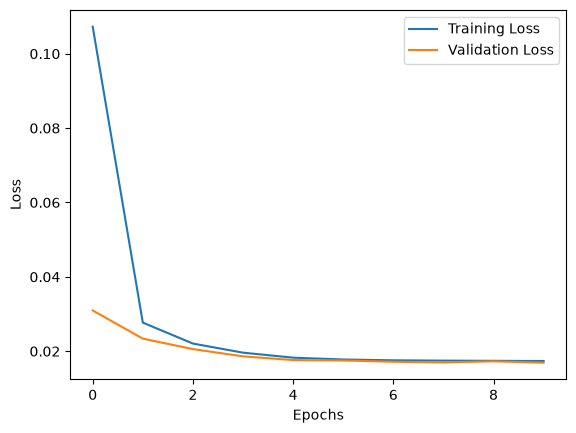

In [16]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [19]:
train_pred = model.predict(x_train)

train_errors = np.mean(
    np.square(x_train-train_pred),
    axis=(1,2)
)

56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


In [20]:
threshold = np.percentile(train_errors, 95)

print(threshold)

0.021629777024227262


In [21]:
test_pred = model.predict(x_test)

test_error = np.mean(
    np.square(x_test-test_pred), axis=(1,2)
)

y_pred = (test_error > threshold).astype(int)

print("Detected Anomalies: ", np.sum(y_pred))

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
Detected Anomalies:  121


In [22]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[460  24]
 [415  97]]

Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.95      0.68       484
           1       0.80      0.19      0.31       512

    accuracy                           0.56       996
   macro avg       0.66      0.57      0.49       996
weighted avg       0.67      0.56      0.49       996

